# Prepare the Tabula Sapiens dataset\n
\n
Download or extract the source H5AD if needed, select a reproducible sample, and build a PCA feature matrix. This notebook saves the feature matrix, tissue labels, cell-type labels, selected source rows, and a manifest under `data/tabula_sapiens/cache/`. Run it again only when you want to change the sample or preprocessing settings.\n

In [1]:
%load_ext autoreload
%autoreload 2

%config InlineBackend.figure_format = 'retina'

from pathlib import Path
import json
import sys
import shutil
import zipfile
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "pyproject.toml").is_file()
     and (path / "imste" / "__init__.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Could not locate the IMSTE repository from the notebook working directory.")
for local_path in (PROJECT_ROOT, PROJECT_ROOT / "notebooks" / "src"):
    local_path = str(local_path)
    if local_path in sys.path:
        sys.path.remove(local_path)
    sys.path.insert(0, local_path)
import imste
if not Path(imste.__file__).resolve().is_relative_to(PROJECT_ROOT.resolve()):
    raise RuntimeError("This kernel loaded IMSTE from another location; restart and run from the top.")
from imste import IteratedMinimumSpanningTreeEmbedder

DATA_DIR = PROJECT_ROOT / "data" / "tabula_sapiens"
DATA_DIR.mkdir(parents=True, exist_ok=True)
ARCHIVE_PATH = DATA_DIR / "TabulaSapiens_v1.h5ad.zip"
H5AD_PATH = DATA_DIR / "TabulaSapiens.h5ad"
if not H5AD_PATH.is_file():
    if not ARCHIVE_PATH.is_file():
        raise FileNotFoundError(f"Expected the dataset archive at {ARCHIVE_PATH}.")
    try:
        with zipfile.ZipFile(ARCHIVE_PATH) as archive:
            h5ad_members = [name for name in archive.namelist() if name.lower().endswith(".h5ad")]
            if len(h5ad_members) != 1:
                raise RuntimeError(f"Expected one H5AD file in {ARCHIVE_PATH.name}; found {h5ad_members}.")
            member = archive.getinfo(h5ad_members[0])
            required_bytes = member.file_size + 1_000_000_000
            if shutil.disk_usage(DATA_DIR).free < required_bytes:
                raise OSError(
                    f"Not enough free space to extract {member.file_size / 1e9:.1f} GB; "
                    f"need at least {required_bytes / 1e9:.1f} GB free."
                )
            print(f"Extracting {member.filename} ({member.file_size / 1e9:.1f} GB)...")
            with archive.open(member) as source, H5AD_PATH.open("wb") as destination:
                shutil.copyfileobj(source, destination, length=16 * 1024 * 1024)
    except zipfile.BadZipFile as error:
        raise RuntimeError(
            "The Tabula Sapiens ZIP is incomplete or invalid. Wait for the download to finish, then rerun this cell."
        ) from error
    print(f"Extracted dataset to {H5AD_PATH}; the source ZIP is retained.")

RANDOM_STATE = 42
MAX_CELLS_PER_CLASS = 5000  # Set to None to use every cell.
MIN_CELLS_PER_CELL_TYPE = 5000  # Exclude cell types with fewer source cells; set to None to disable.
SAMPLE_BY = "cell_type"  # "cell_type" or "tissue"; both rows use this same sample.
TARGET_SUM = 10_000
N_HVG = 4_000
N_PCS = 300
METRIC = 'euclidean'

## Load annotations and cap cells per class

The source object is opened in backed mode so the full expression matrix is not loaded just to inspect labels. Cell types below `MIN_CELLS_PER_CELL_TYPE` source cells are filtered out first. Then we sample up to `MAX_CELLS_PER_CLASS` cells within each class of `SAMPLE_BY`; setting either threshold to `None` disables that filter. A fixed random seed makes the selected cells reproducible.

Source: 483,152 cells × 58,870 genes
Cell-type filter: kept 30/177 types with at least 5000 cells; selected 150,000 of 483,152 source cells.
Sample cap: 5000 cells per cell_type class.
Tissue annotation: organ_tissue; cell-type annotation: cell_ontology_class


,organ_tissue,cell_ontology_class,cells
0,Bladder,b cell,60
1,Bladder,fibroblast,873
2,Bladder,macrophage,773
3,Bladder,nk cell,271
4,Bladder,plasma cell,491
5,Bladder,t cell,987
6,Blood,"cd4-positive, alpha-beta t cell",1016
7,Blood,"cd8-positive, alpha-beta t cell",498
8,Blood,classical monocyte,2708
9,Blood,erythrocyte,4753


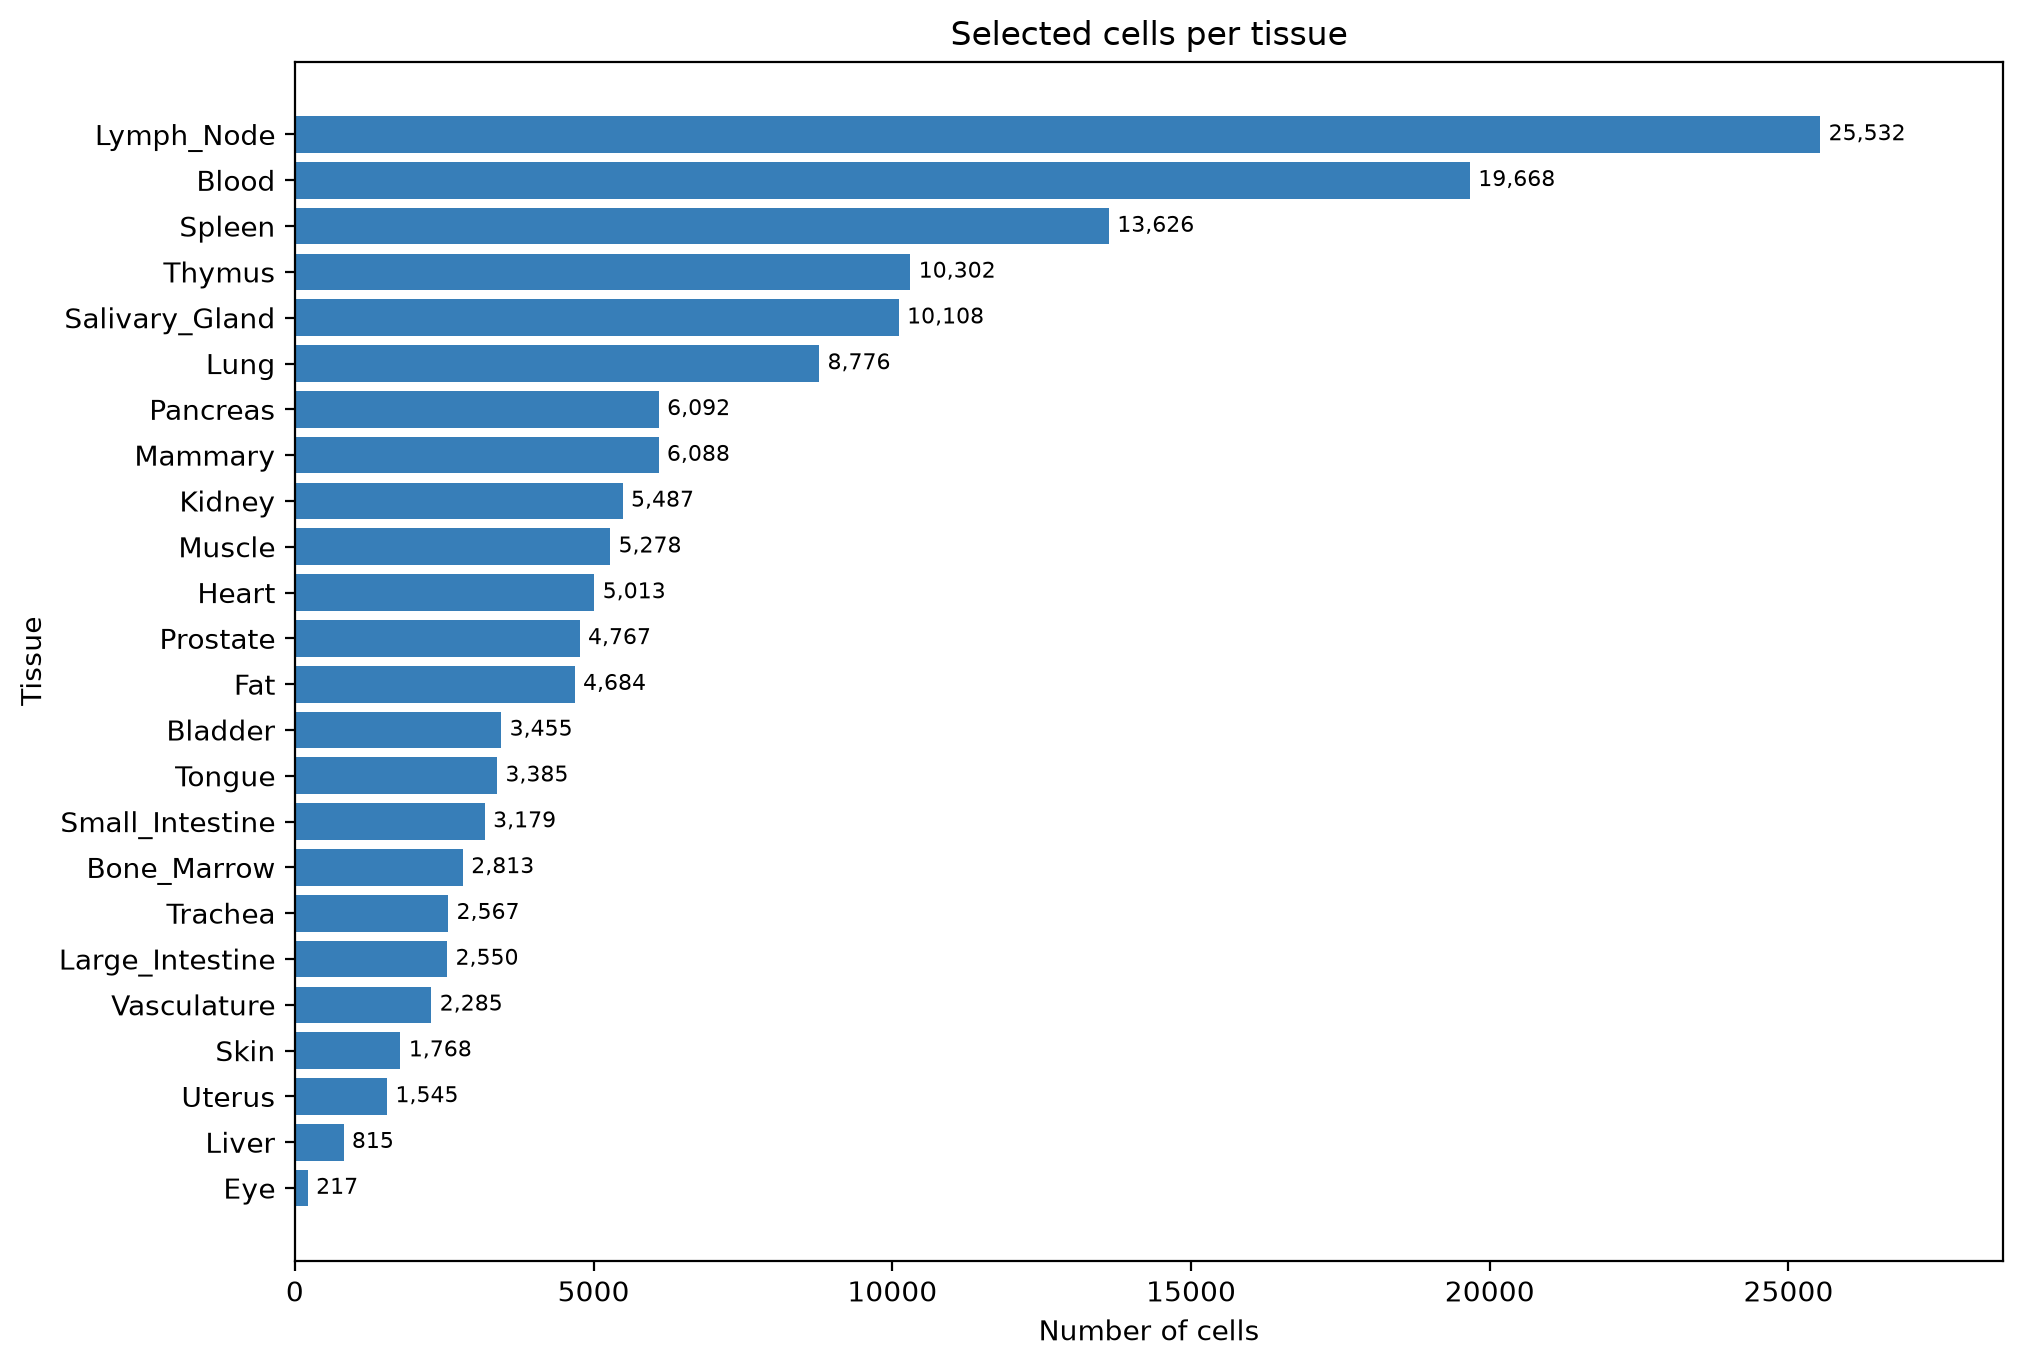

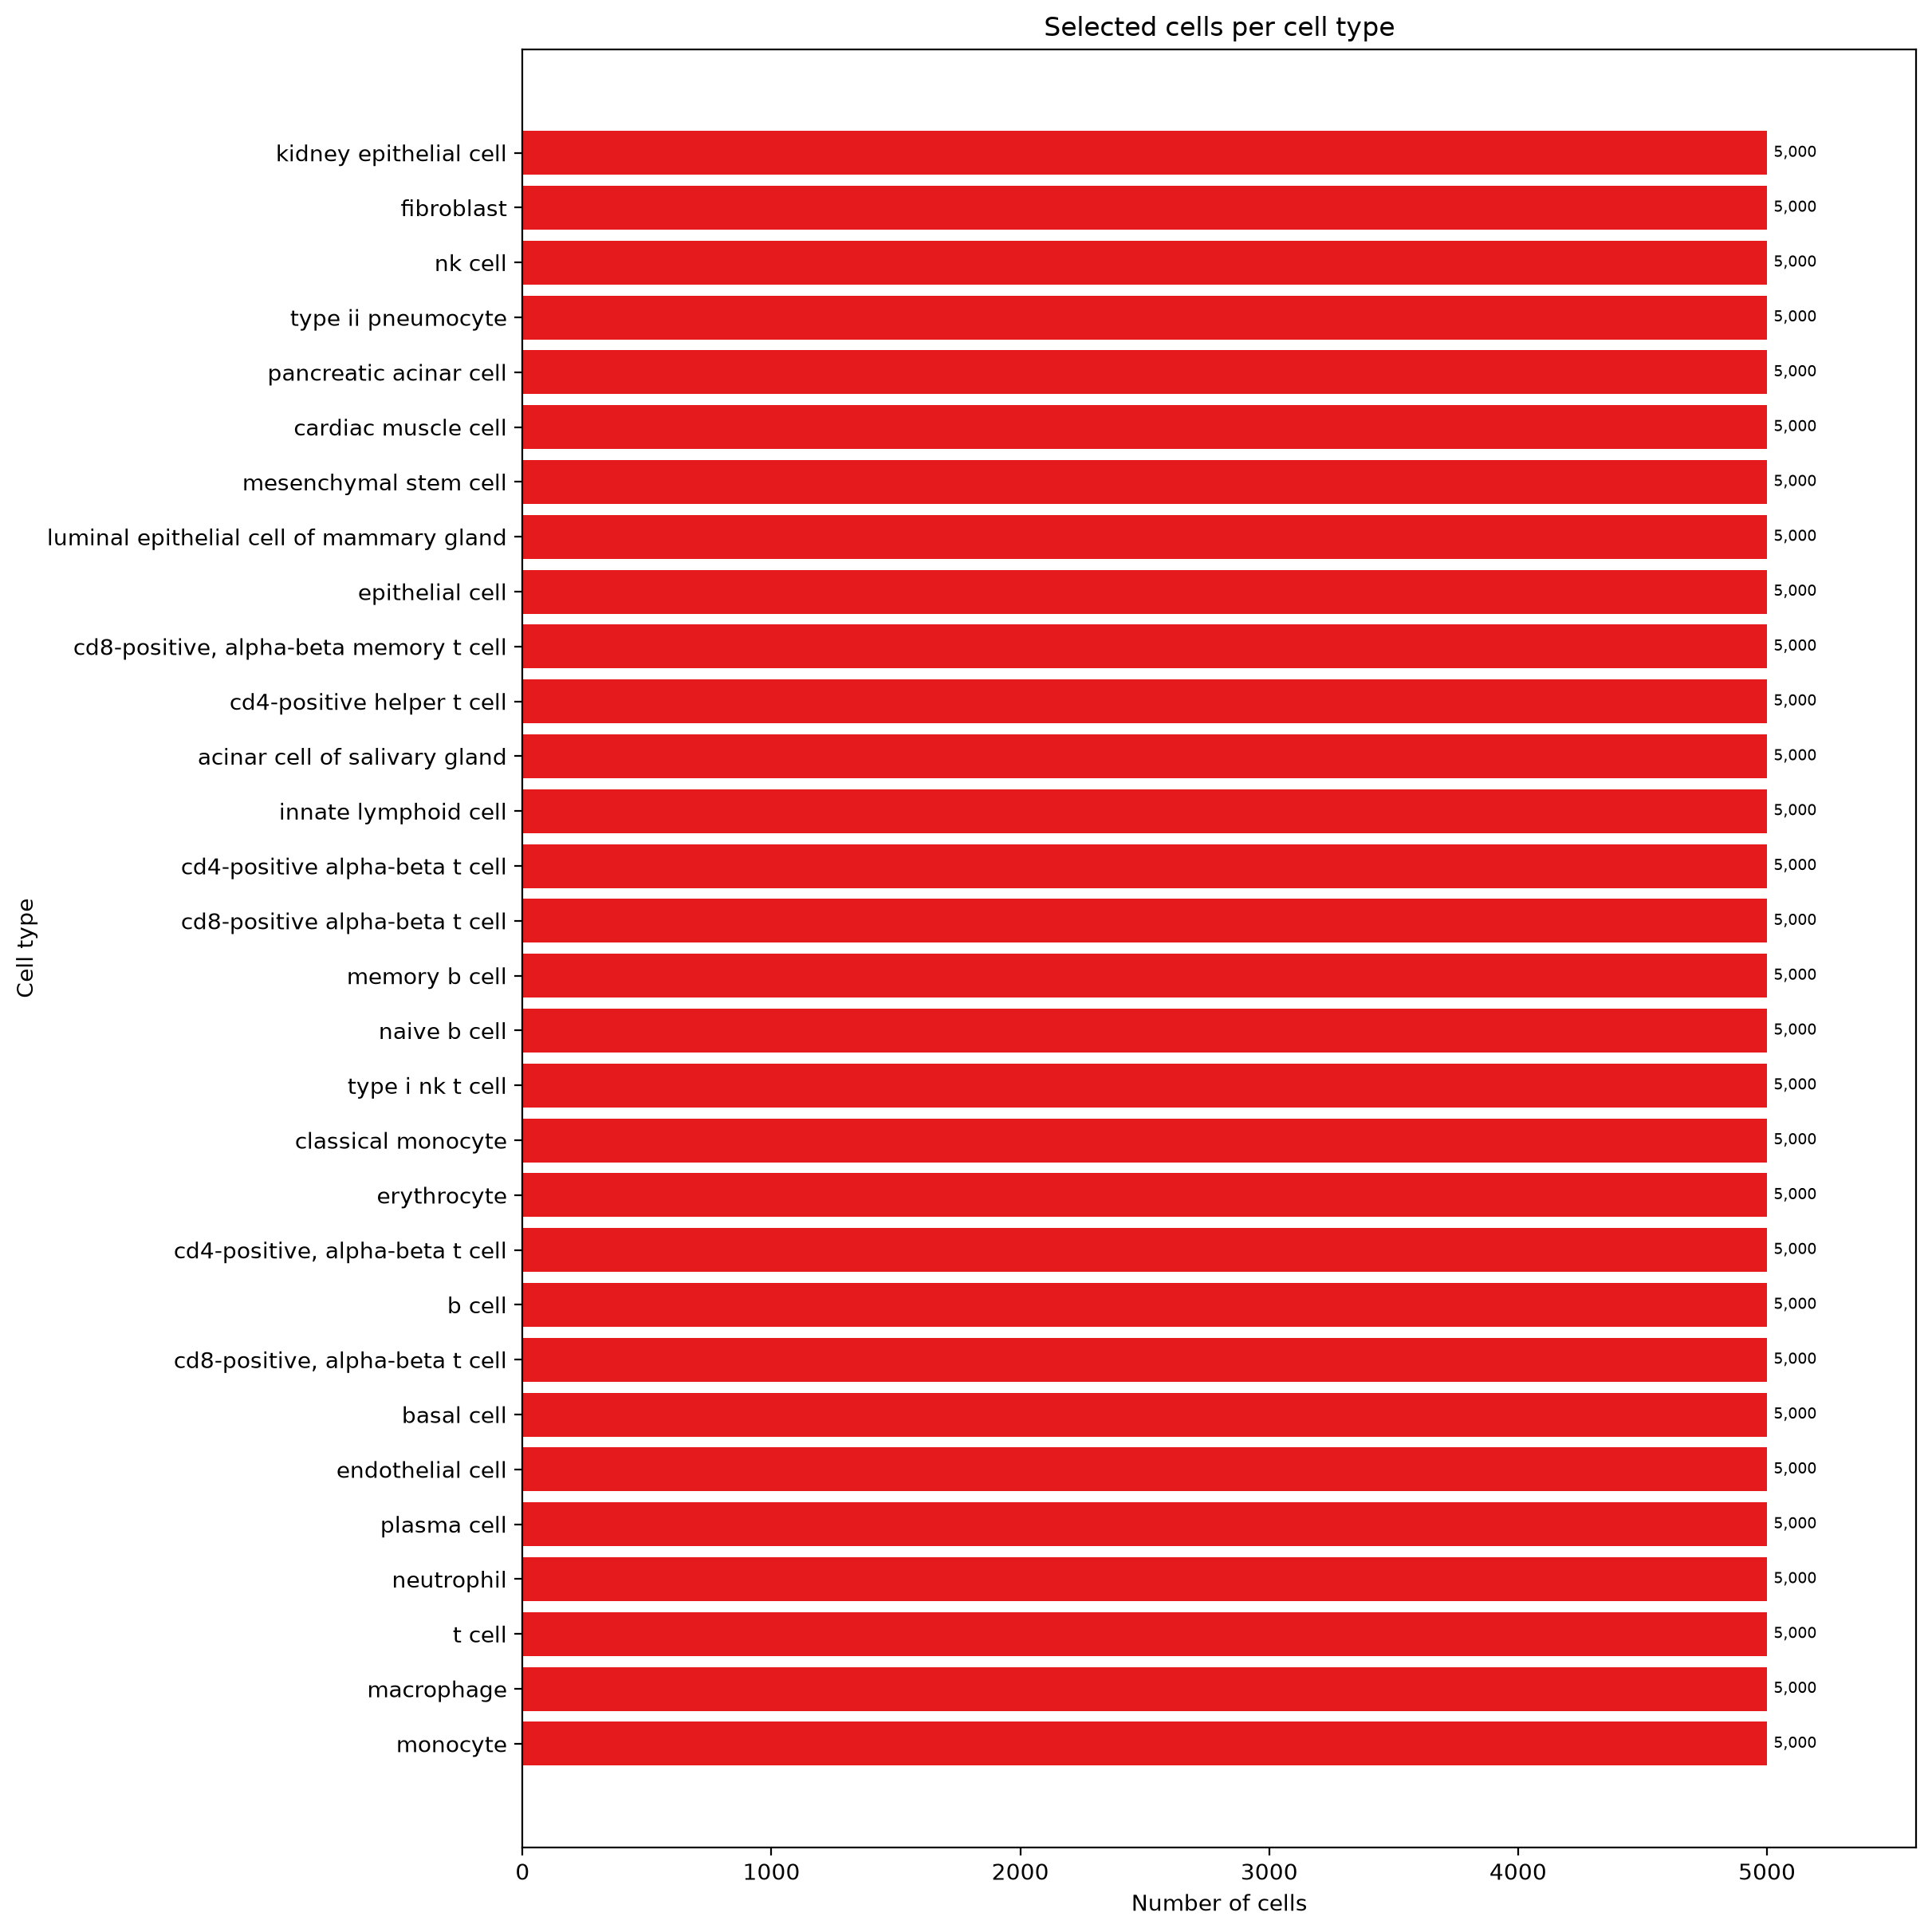

In [2]:
adata_source = sc.read_h5ad(H5AD_PATH, backed="r")

# Tabula Sapiens v1 annotation names; prefer the atlas' ontology cell types.
def first_available(columns, candidates, description):
    for name in candidates:
        if name in columns:
            return name
    raise KeyError(f"Could not find {description}; available obs columns: {list(columns)}")

tissue_column = first_available(
    adata_source.obs.columns, ("organ_tissue", "tissue", "tissue_general"), "tissue annotation"
)
cell_type_column = first_available(
    adata_source.obs.columns, ("cell_ontology_class", "cell_type", "free_annotation"), "cell-type annotation"
)
if SAMPLE_BY not in {"cell_type", "tissue"}:
    raise ValueError("SAMPLE_BY must be 'cell_type' or 'tissue'.")
sampling_column = cell_type_column if SAMPLE_BY == "cell_type" else tissue_column

obs = adata_source.obs[[tissue_column, cell_type_column]].copy()
obs = obs.astype("string").fillna("unannotated").astype(str)
cell_type_source_counts = obs[cell_type_column].value_counts()
if MIN_CELLS_PER_CELL_TYPE is not None:
    if not isinstance(MIN_CELLS_PER_CELL_TYPE, int) or MIN_CELLS_PER_CELL_TYPE < 1:
        raise ValueError("MIN_CELLS_PER_CELL_TYPE must be a positive integer or None.")
    retained_types = cell_type_source_counts[
        cell_type_source_counts >= MIN_CELLS_PER_CELL_TYPE
    ].index
else:
    retained_types = cell_type_source_counts.index

eligible_mask = obs[cell_type_column].isin(retained_types).to_numpy()
eligible_indices = np.flatnonzero(eligible_mask)
if not len(eligible_indices):
    raise ValueError("The minimum cell-type threshold removed all cells.")

if MAX_CELLS_PER_CLASS is not None:
    if not isinstance(MAX_CELLS_PER_CLASS, int) or MAX_CELLS_PER_CLASS < 1:
        raise ValueError("MAX_CELLS_PER_CLASS must be a positive integer or None.")
    rng = np.random.default_rng(RANDOM_STATE)
    selected_groups = []
    eligible_group_values = obs.iloc[eligible_indices][sampling_column].to_numpy()
    for class_name in pd.unique(eligible_group_values):
        group_members = eligible_indices[eligible_group_values == class_name]
        selected_groups.append(
            rng.choice(group_members, min(len(group_members), MAX_CELLS_PER_CLASS), replace=False)
        )
    selected_indices = np.sort(np.concatenate(selected_groups))
else:
    selected_indices = eligible_indices

print(f"Source: {adata_source.n_obs:,} cells × {adata_source.n_vars:,} genes")
print(
    f"Cell-type filter: kept {len(retained_types):,}/{len(cell_type_source_counts):,} types "
    f"with at least {MIN_CELLS_PER_CELL_TYPE if MIN_CELLS_PER_CELL_TYPE is not None else 'any'} cells; "
    f"selected {len(selected_indices):,} of {adata_source.n_obs:,} source cells."
)
print(f"Sample cap: {MAX_CELLS_PER_CLASS} cells per {SAMPLE_BY} class.")
print(f"Tissue annotation: {tissue_column}; cell-type annotation: {cell_type_column}")
display(obs.iloc[selected_indices].groupby([tissue_column, cell_type_column], observed=True).size()
        .rename("cells").reset_index().head(20))

selected_obs = obs.iloc[selected_indices]
tissue_counts = selected_obs[tissue_column].value_counts().sort_values()
cell_type_counts = selected_obs[cell_type_column].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, max(5, 0.28 * len(tissue_counts))), constrained_layout=True)
bars = ax.barh(tissue_counts.index, tissue_counts.values, color="#377eb8")
ax.bar_label(bars, fmt="{:,.0f}", padding=3, fontsize=8)
ax.set_xlim(0, tissue_counts.max() * 1.12)
ax.set_title("Selected cells per tissue")
ax.set_xlabel("Number of cells")
ax.set_ylabel("Tissue")
plt.show()

fig, ax = plt.subplots(figsize=(12, max(12, 0.17 * len(cell_type_counts))), constrained_layout=True)
bars = ax.barh(cell_type_counts.index, cell_type_counts.values, color="#e41a1c")
ax.bar_label(bars, fmt="{:,.0f}", padding=3, fontsize=7)
ax.set_xlim(0, cell_type_counts.max() * 1.12)
ax.set_title("Selected cells per cell type")
ax.set_xlabel("Number of cells")
ax.set_ylabel("Cell type")
plt.show()

## Normalize counts and compute the shared feature matrix

Use the raw count layer, normalize each cell to `TARGET_SUM`, and apply `log1p`. Then select highly variable genes, scale, and reduce to `N_PCS` principal components. These PCs are the shared high-dimensional input for both UMAP and IMSTE.

In [3]:
# Tabula Sapiens v1 stores unnormalized counts in layers['raw_counts'].
if "raw_counts" not in adata_source.layers:
    raise KeyError(f"Expected layers['raw_counts']; available layers: {list(adata_source.layers.keys())}")

adata_sample = adata_source[selected_indices].to_memory()
adata_source.file.close()
adata = sc.AnnData(
    X=adata_sample.layers["raw_counts"].copy(),
    obs=obs.iloc[selected_indices].copy(),
    var=adata_sample.var.copy(),
)
del adata_sample

# Standard single-cell normalization: equalize total counts per cell, then log transform.
sc.pp.normalize_total(adata, target_sum=TARGET_SUM)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, n_top_genes=N_HVG, flavor="seurat")
adata = adata[:, adata.var["highly_variable"]].copy()
sc.pp.scale(adata, zero_center=False, max_value=10)
if not np.isfinite(adata.X.data).all():
    raise ValueError("Scaled expression matrix contains non-finite values before PCA.")
sc.tl.pca(
    adata,
    n_comps=min(N_PCS, adata.n_obs - 1, adata.n_vars - 1),
    zero_center=False,  # Sparse truncated SVD avoids implicit centering and densification.
    random_state=RANDOM_STATE,
)
X = np.asarray(adata.obsm["X_pca"], dtype=np.float32)
if not np.isfinite(X).all():
    raise ValueError("PCA produced non-finite coordinates; inspect counts and scaling.")
tissue_labels = adata.obs[tissue_column].astype(str).to_numpy()
cell_type_labels = adata.obs[cell_type_column].astype(str).to_numpy()
print(f"Feature matrix: {X.shape[0]:,} cells × {X.shape[1]} PCs from {adata.n_vars:,} HVGs")
display(pd.DataFrame({"cells": [len(X)], "tissues": [pd.Series(tissue_labels).nunique()],
                     "cell types": [pd.Series(cell_type_labels).nunique()]}))

# Save the sampled feature matrix and both annotations for the embedding notebook.
CACHE_DIR = DATA_DIR / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
PREPARED_CACHE = CACHE_DIR / "tabula_sapiens_pca_sample.npz"
PREPARED_MANIFEST = CACHE_DIR / "tabula_sapiens_pca_sample_manifest.json"
TEMP_CACHE = CACHE_DIR / "tabula_sapiens_pca_sample.tmp.npz"
TEMP_MANIFEST = CACHE_DIR / "tabula_sapiens_pca_sample_manifest.tmp.json"
np.savez_compressed(
    TEMP_CACHE,
    X=X,
    tissue_labels=np.asarray(tissue_labels, dtype=str),
    cell_type_labels=np.asarray(cell_type_labels, dtype=str),
    selected_indices=np.asarray(selected_indices, dtype=np.int64),
    hvg_names=np.asarray(adata.var_names, dtype=str),
)
TEMP_CACHE.replace(PREPARED_CACHE)
manifest = {
    "dataset": "Tabula Sapiens v1",
    "source_file": "data/tabula_sapiens/TabulaSapiens.h5ad",
    "random_state": RANDOM_STATE,
    "sample_by": SAMPLE_BY,
    "max_cells_per_class": MAX_CELLS_PER_CLASS,
    "min_cells_per_cell_type": MIN_CELLS_PER_CELL_TYPE,
    "target_sum": TARGET_SUM,
    "n_hvg_requested": N_HVG,
    "n_hvg_used": int(adata.n_vars),
    "n_pcs_requested": N_PCS,
    "n_pcs_used": int(X.shape[1]),
    "tissue_column": tissue_column,
    "cell_type_column": cell_type_column,
    "n_cells": int(X.shape[0]),
    "n_tissues": int(pd.Series(tissue_labels).nunique()),
    "n_cell_types": int(pd.Series(cell_type_labels).nunique()),
    "feature_shape": [int(value) for value in X.shape],
}
TEMP_MANIFEST.write_text(json.dumps(manifest, indent=2) + "\n")
TEMP_MANIFEST.replace(PREPARED_MANIFEST)
print(f"Saved prepared features: {PREPARED_CACHE}")
print(f"Saved manifest: {PREPARED_MANIFEST}")


/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:619: RuntimeWarning: divide by zero encountered in matmul
  U = Q @ Uhat
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:619: RuntimeWarning: overflow encountered in matmul
  U = Q @ Uhat
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:619: RuntimeWarning: invalid value encountered in matmul
  U = Q @ Uhat


Feature matrix: 150,000 cells × 300 PCs from 4,000 HVGs


,cells,tissues,cell types
0,150000,24,30


Saved prepared features: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/IteratedMinimumSpanningTree/data/tabula_sapiens/cache/tabula_sapiens_pca_sample.npz
Saved manifest: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/IteratedMinimumSpanningTree/data/tabula_sapiens/cache/tabula_sapiens_pca_sample_manifest.json
